In [2]:
%run ./dataManipulationFunctions.ipynb

/usr/local/lib/python3.11/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.3, the latest is 0.5.4.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [3]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

In [4]:
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

2024-01-14 15:25:59.644564: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0]
# No of men vs no of women
print(pd.DataFrame(y).value_counts())
# % of men vs % of women
print(pd.DataFrame(y).value_counts(normalize=True) * 100)

#MALE - 0, FEMALE - 1

0.0    503
1.0    137
Name: count, dtype: int64
0.0    78.59375
1.0    21.40625
Name: proportion, dtype: float64


In [6]:
from sklearn.model_selection import train_test_split
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]

newX = np.concatenate([np.array(metadata)[:,0:2], X], axis=1)

IDsFeatures = pd.DataFrame(newX, columns=['clipID', 'speakerID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness'])

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

features = pd.DataFrame(X)
target = pd.DataFrame(y, columns=['Gender'])
bothIDs = pd.DataFrame( np.array(metadata)[:,0:2], columns=['clipID','speakerID'])

n_splits = 5
kFold = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=1)

# Initialize an array to store fold assignments
fold_assignments = np.zeros_like(bothIDs['speakerID'])

classifier = RandomForestClassifier()

# Assign folds based on groups (speakerID column)
for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=bothIDs['speakerID'])):
    fold_assignments[test_index] = fold
    
    X_train, X_test = features.iloc[train_index], features.iloc[test_index]
    y_train = target.iloc[train_index]
    classifier.fit(X_train, y_train)
    y[test_index] = classifier.predict(X_test)


for fold_number in range(n_splits):
    entries_in_fold = bothIDs.loc[fold_assignments == fold_number, 'clipID'].tolist()
    data = features.loc[fold_assignments == fold_number]
    predictions_in_fold = target.loc[fold_assignments == fold_number, 'Gender'].tolist()
    # print(f"Entries in fold {fold_number + 1}: {entries_in_fold}")
    # print(f"Predictions in fold {fold_number + 1}: {predictions_in_fold}")

NameError: name 'RandomForestClassifier' is not defined

In [8]:
def calculateResults(model, X, y):
    features = pd.DataFrame(X)
    target = pd.DataFrame(y, columns=['Gender'])
    bothIDs = pd.DataFrame( np.array(metadata)[:,0:2], columns=['clipID','speakerID'])
    f1Scores=[]
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]
    for trainIndex, valIndex in kFold.split(X, y):
        X_tr, X_te = X[trainIndex], X[valIndex]
        y_tr, y_te = y[trainIndex], y[valIndex]
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
        
    # display(pd.DataFrame({'f1 score': f1Scores, 'confusion matrix': confusionMatrices}))
    result = pd.DataFrame({'Average f1 score': np.mean(f1Scores), 'Total confusion matrix': ([confusionMatrixTotal])})
    return (result)

In [9]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [10]:
# from sklearn.model_selection import RepeatedStratifiedKFold
# from sklearn.neighbors import KNeighborsClassifier
# #n_splits - k no of folds
# # n_repeats, number of times cross-validation is repeated

# models=[LogisticRegression(solver='liblinear',class_weight='balanced'), KNeighborsClassifier(n_neighbors=2, weights='distance'), DecisionTreeClassifier(class_weight={0:3.6715328467153285,1:1})]
# for model in models:
#     cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
#     scores = cross_val_score(model, X_trainVal, y_trainVal, scoring="f1", cv=cv)

#     print(model,(scores))


Splitting Dataset into two, a set for training and validation data and one for testing data.

K fold validation is used as a way to create a function which takes an algoritm and using k folds, calculates its f1 score.  
    K fold splits the train set into k train/validation sets which are used to determine hyperparameters etc.

In [16]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

logisticReg = LogisticRegression(solver='liblinear',class_weight='balanced')
Kneightbors = KNeighborsClassifier(n_neighbors=5, weights='distance')
randomForest = RandomForestClassifier(n_estimators=200, class_weight='balanced')
decisionTree=DecisionTreeClassifier(class_weight={0:3.6715328467153285,1:1})
SVM = SVC(kernel='poly', C=6, degree=5)

kFold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

def calculateResults(model, X, y):
    f1Scores=[]
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]
    y = y.astype(int)
    for trainIndex, valIndex in kFold.split(X, y):
        X_tr, X_te = X[trainIndex], X[valIndex]
        y_tr, y_te = y[trainIndex], y[valIndex]
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
        
    # display(pd.DataFrame({'f1 score': f1Scores, 'confusion matrix': confusionMatrices}))
    result = pd.DataFrame({'Average f1 score': np.mean(f1Scores), 'Total confusion matrix': ([confusionMatrixTotal])})
    return (result)

algorithmName = ["Logistic Regression", "Random Forest", "Decision Tree", "SVM", "K neighbours"]
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]
df = pd.DataFrame()
for i in range (len(algorithms)):
    df = pd.concat([df,calculateResults(algorithms[i],X_train, y_train)])
df.index = algorithmName

display(df)


,Average f1 score,Total confusion matrix
Logistic Regression,0.476279,"[[274, 128], [36, 74]]"
Random Forest,0.309931,"[[312, 90], [73, 37]]"
Decision Tree,0.266976,"[[360, 42], [86, 24]]"
SVM,0.254371,"[[370, 32], [89, 21]]"
K neighbours,0.294134,"[[366, 36], [84, 26]]"


In [17]:
def calculateFinal(model):
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    f1Score = (f1_score(y_test, prediction))
    confusionMatrix =(confusion_matrix(y_test, prediction))
    return f1Score, confusionMatrix

f1Scores = [calculateResults(logisticReg, X_test, y_test)['Average f1 score'],calculateResults(randomForest, X_test, y_test)['Average f1 score'], calculateResults(decisionTree, X_test, y_test)['Average f1 score'], calculateResults(SVM, X_test, y_test)['Average f1 score'], calculateResults(Kneightbors, X_test, y_test)['Average f1 score'] ]
confusionMatrices = [calculateResults(logisticReg, X_test, y_test)['Total confusion matrix'],calculateResults(randomForest, X_test, y_test)['Total confusion matrix'], calculateResults(decisionTree, X_test, y_test)['Total confusion matrix'], calculateResults(SVM, X_test, y_test)['Total confusion matrix'], calculateResults(Kneightbors, X_test, y_test)['Total confusion matrix'] ]

confusionMatricesF = [calculateFinal(logisticReg)[1],calculateFinal(randomForest)[1], calculateFinal(decisionTree)[1], calculateFinal(SVM)[1], calculateFinal(Kneightbors)[1] ]

algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]

testSetResults = pd.DataFrame()
for i in range (len(algorithms)):
    testSetResults = pd.concat([testSetResults, calculateResults(algorithms[i], X_test, y_test)])
    # print(calculateFinal(algorithms[i])[1], calculateResults(algorithms[i], X_test, y_test)['Total confusion matrix'])
testSetResults.index = algorithmName
display(testSetResults)


,Average f1 score,Total confusion matrix
Logistic Regression,0.444365,"[[67, 34], [9, 18]]"
Random Forest,0.256667,"[[87, 14], [21, 6]]"
Decision Tree,0.277143,"[[85, 16], [20, 7]]"
SVM,0.307143,"[[88, 13], [19, 8]]"
K neighbours,0.156667,"[[90, 11], [24, 3]]"


In [18]:
from scipy import stats

binomialTestResults = pd.DataFrame()
confusionMatrices = [calculateResults(logisticReg, X_test, y_test)['Total confusion matrix'],calculateResults(randomForest, X_test, y_test)['Total confusion matrix'], calculateResults(decisionTree, X_test, y_test)['Total confusion matrix'], calculateResults(SVM, X_test, y_test)['Total confusion matrix'], calculateResults(Kneightbors, X_test, y_test)['Total confusion matrix'] ]
# confusionMatricesF = [calculateFinal(logisticReg)[1],calculateFinal(randomForest)[1], calculateFinal(decisionTree)[1], calculateFinal(SVM)[1], calculateFinal(Kneightbors)[1] ]


for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y_test.size
    # confusionMatrix = getTestResults()['Total confusion matrix'][algorithm]
    # print(confusionMatrix)
    trueNeg = confusionMatrices[i][0][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices[i][0][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices[i][0][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices[i][0][1][1]  #correct female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])

binomialTestResults.rename(columns={0: 'f1 value for test set', 1: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = algorithmName
display(binomialTestResults)

,f1 value for test set,Binomial test p value
Logistic Regression,0.444365,1.000000
Random Forest,0.290000,0.135569
Decision Tree,0.310476,0.303370
SVM,0.307143,0.039552
K neighbours,0.156667,0.135569


## PCA

- a dimensionality reduction method
- transforms large set of variables into smaller one containing most of the info of the large set

- Step 1 - Standarization
- Step 2 - Covarince Matrix Computation: to see if there is a relationship between the variables

In [11]:
from sklearn.decomposition import PCA

In [163]:
data = medianScoresPerClip()[:,1:]
genderList = to_categorical(labelencoder.fit_transform(listOfGenders))[:,0]

labels = np.reshape(genderList, (640,1))
finalData = np.concatenate([data, labels], axis=1)
finalDataset = pd.DataFrame(finalData)
finalDataset.columns = columns[1:]
finalDataset['Gender'].replace(0, 'Male',inplace=True)
finalDataset['Gender'].replace(1, 'Female',inplace=True)

x = finalDataset.loc[:, columns[1:6]].values
x = StandardScaler().fit_transform(x)

feat_cols = ['feature'+ str(i) for i in range(x.shape[1])]
normalised = pd.DataFrame(x,columns=feat_cols)
normalised.head()

pca = PCA(n_components=2)
princComp = pca.fit_transform(x)
df_pca = pd.DataFrame(data = princComp
             , columns = ['principal component 1', 'principal component 2'])

print('Variance of the pricipal components: {}'.format(pca.explained_variance_ratio_))


Variance of the pricipal components: [0.35845079 0.29290806]


In [164]:
# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT

pca = PCA(n_components=5)
princComp = pca.fit_transform(x)
print('Amount of variance per principal component: {}'.format(pca.explained_variance_ratio_))

# Two components result to 65% of variance while we need 4 to get 90%

Amount of variation per principal component: [0.35845079 0.29290806 0.15350095 0.10301126 0.09212895]


<Figure size 640x480 with 0 Axes>

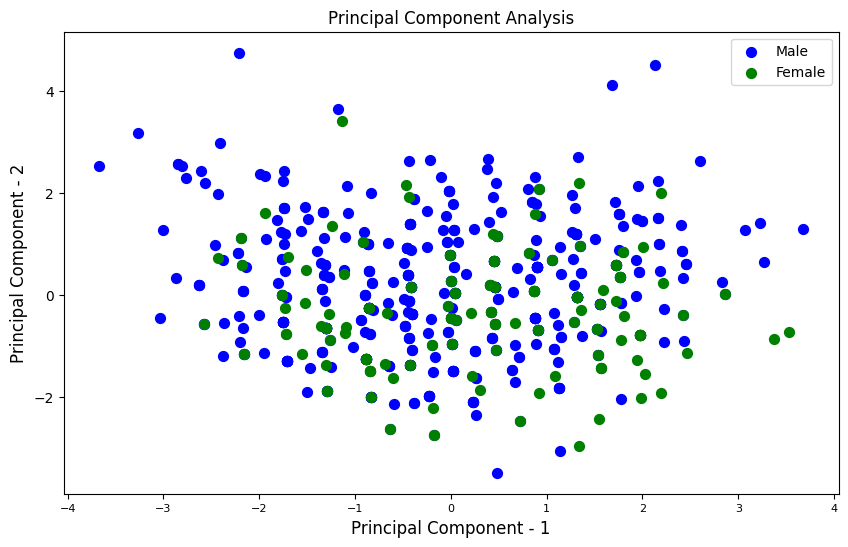

In [137]:
plt.figure()
plt.figure(figsize=(10,6))
plt.xticks(fontsize=8)
plt.yticks(fontsize=10)
plt.xlabel('Principal Component - 1',fontsize=12)
plt.ylabel('Principal Component - 2',fontsize=12)
plt.title("Principal Component Analysis",fontsize=12)
targets = ['Male', 'Female']
colors = ['b', 'g']
for target, color in zip(targets,colors):
    k = finalDataset['Gender'] == target
    plt.scatter(df_pca.loc[k, 'principal component 1']
               , df_pca.loc[k, 'principal component 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 10})

Excluding Extraversion since it is not statistically significant

Explained variation per principal component: [0.37594846 0.31745555]


<Figure size 640x480 with 0 Axes>

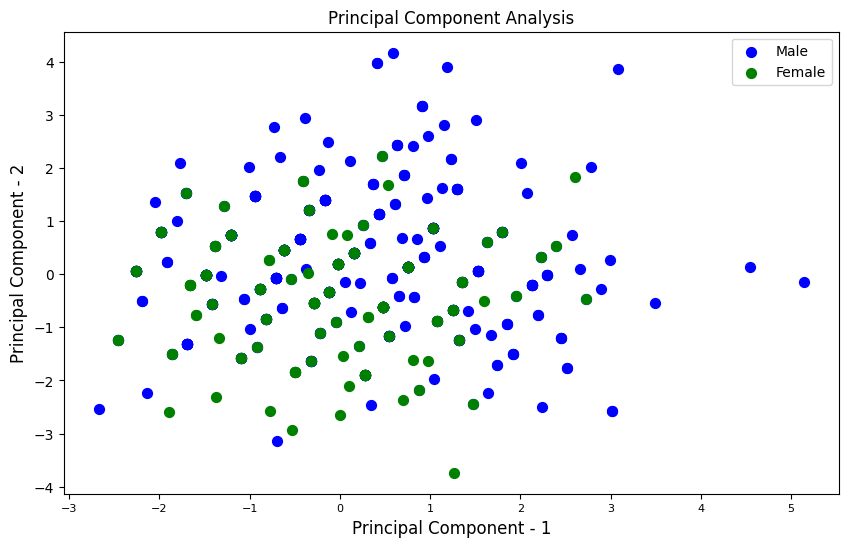

In [138]:
data = medianScoresPerClip()[:,2:]
genderList = to_categorical(labelencoder.fit_transform(listOfGenders))[:,0]

labels = np.reshape(genderList, (640,1))
finalData = np.concatenate([data, labels], axis=1)
finalDataset = pd.DataFrame(finalData)
finalDataset.columns = columns[2:]
finalDataset['Gender'].replace(0, 'Male',inplace=True)
finalDataset['Gender'].replace(1, 'Female',inplace=True)


x = finalDataset.loc[:, columns[2:6]].values
x = StandardScaler().fit_transform(x)

feat_cols = ['feature'+str(i) for i in range(x.shape[1])]
normalised = pd.DataFrame(x,columns=feat_cols)
normalised.head()

pca = PCA(n_components=2)
princComp = pca.fit_transform(x)
df_pca = pd.DataFrame(data = princComp
             , columns = ['principal component 1', 'principal component 2'])


print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

plt.figure()
plt.figure(figsize=(10,6))
plt.xticks(fontsize=8)
plt.yticks(fontsize=10)
plt.xlabel('Principal Component - 1',fontsize=12)
plt.ylabel('Principal Component - 2',fontsize=12)
plt.title("Principal Component Analysis",fontsize=12)
targets = ['Male', 'Female']
colors = ['b', 'g']
for target, color in zip(targets,colors):
    k = finalDataset['Gender'] == target
    plt.scatter(df_pca.loc[k, 'principal component 1']
               , df_pca.loc[k, 'principal component 2'], c = color, s = 50)

plt.legend(targets,prop={'size': 10})

In [64]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

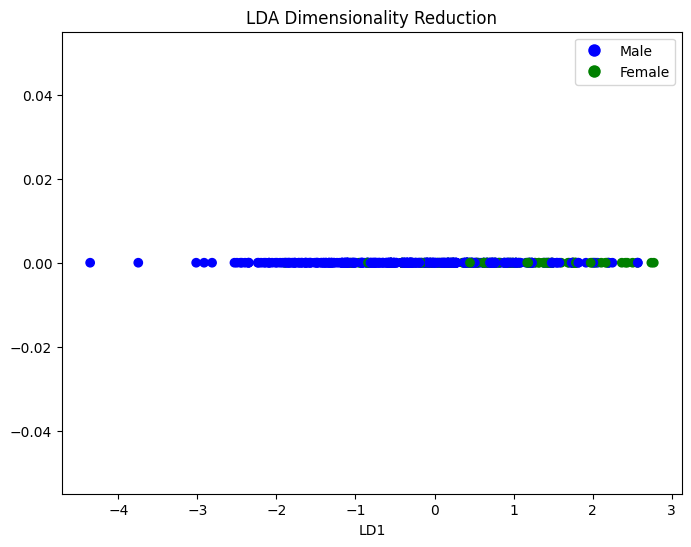

In [119]:

lda = LinearDiscriminantAnalysis(n_components=1)  # Reduce to 1 component for binary classification
X_lda = lda.fit_transform(data, y)

# Plotting the transformed data
plt.figure(figsize=(8, 6))
plt.scatter(X_lda, np.zeros_like(X_lda), c=np.where(y == 0, 'blue', 'green'), label='Class 0 (Blue) & Class 1 (Green)')
plt.xlabel('LD1')
plt.title('LDA Dimensionality Reduction')
legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='Male', markerfacecolor='blue', markersize=10),
                   plt.Line2D([0], [0], marker='o', color='w', label='Female', markerfacecolor='green', markersize=10)]

plt.show()